In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
np.random.seed(42)
n = 120

tenure = np.random.randint(1, 61, n)
monthly_charges = np.round(np.random.uniform(25, 120, n), 2)
support_calls = np.random.randint(0, 8, n)
contract_months = np.random.choice([1, 12, 24], n, p=[0.45, 0.35, 0.20])
auto_pay = np.random.choice([0, 1], n, p=[0.55, 0.45])

# Build a realistic churn tendency from several customer behaviors
logit = (1.2 - 0.045 * tenure + 0.018 * monthly_charges +
         0.32 * support_calls - 0.045 * contract_months - 0.55 * auto_pay)
probability = 1 / (1 + np.exp(-logit))
churn = np.random.binomial(1, probability)

customers = pd.DataFrame({
    "Tenure_Months": tenure,
    "Monthly_Charges": monthly_charges,
    "Support_Calls": support_calls,
    "Contract_Months": contract_months,
    "Auto_Pay": auto_pay,
    "Churn": churn
})

customers.head()

,Tenure_Months,Monthly_Charges,Support_Calls,Contract_Months,Auto_Pay,Churn
0,39,101.21,0,24,1,0
1,52,32.08,3,24,0,1
2,29,118.75,3,24,0,0
3,15,98.36,0,1,0,1
4,43,43.88,1,1,0,0


In [3]:
print("Rows and columns:", customers.shape)
print("\nMissing values:")
print(customers.isnull().sum())
print("\nChurn counts:")
print(customers["Churn"].value_counts().rename(index={0: "Stayed", 1: "Churned"}))

Rows and columns: (120, 6)

Missing values:
Tenure_Months      0
Monthly_Charges    0
Support_Calls      0
Contract_Months    0
Auto_Pay           0
Churn              0
dtype: int64

Churn counts:
Churn
Churned    90
Stayed     30
Name: count, dtype: int64


In [4]:
summary = customers.groupby("Churn")[["Tenure_Months", "Monthly_Charges", "Support_Calls", "Contract_Months", "Auto_Pay"]].mean().round(2)
summary.index = ["Stayed", "Churned"]
summary

,Tenure_Months,Monthly_Charges,Support_Calls,Contract_Months,Auto_Pay
Stayed,36.53,66.58,2.33,11.17,0.57
Churned,30.29,72.48,4.04,9.34,0.47


<Figure size 800x500 with 0 Axes>

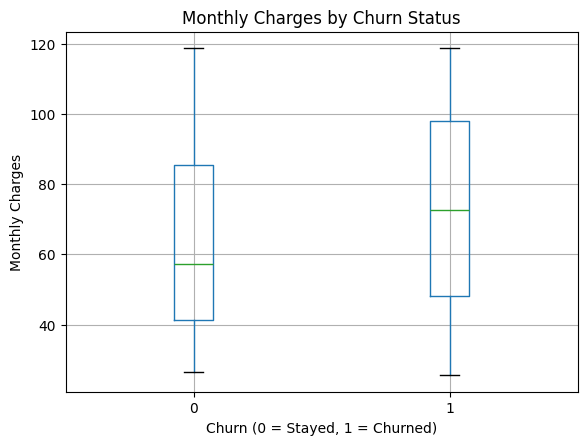

In [5]:
plt.figure(figsize=(8, 5))
customers.boxplot(column="Monthly_Charges", by="Churn")
plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn (0 = Stayed, 1 = Churned)")
plt.ylabel("Monthly Charges")
plt.show()

In [6]:
X = customers.drop(columns="Churn")
y = customers["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 90
Testing rows: 30


In [7]:
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Model trained successfully.")

Model trained successfully.


In [8]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2%}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"], zero_division=0))

Accuracy: 73.33%

Classification report:
              precision    recall  f1-score   support

      Stayed       0.50      0.12      0.20         8
     Churned       0.75      0.95      0.84        22

    accuracy                           0.73        30
   macro avg       0.62      0.54      0.52        30
weighted avg       0.68      0.73      0.67        30



Confusion matrix:
[[ 1  7]
 [ 1 21]]


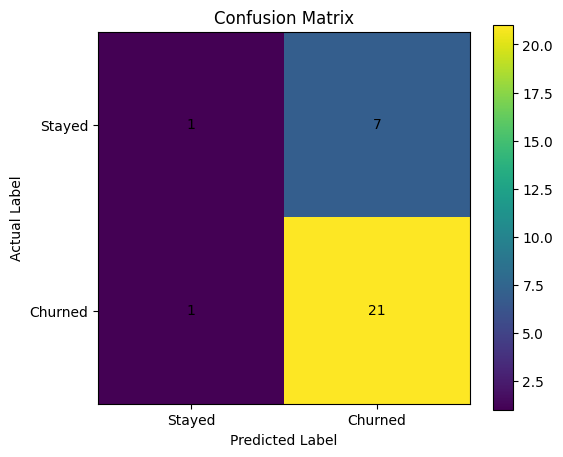

In [9]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1], ["Stayed", "Churned"])
plt.yticks([0, 1], ["Stayed", "Churned"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.colorbar()
plt.show()

In [10]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
}).sort_values("Coefficient", ascending=False)
coefficients

,Feature,Coefficient
2,Support_Calls,0.797911
1,Monthly_Charges,0.094429
4,Auto_Pay,-0.026441
0,Tenure_Months,-0.243440
3,Contract_Months,-0.317823


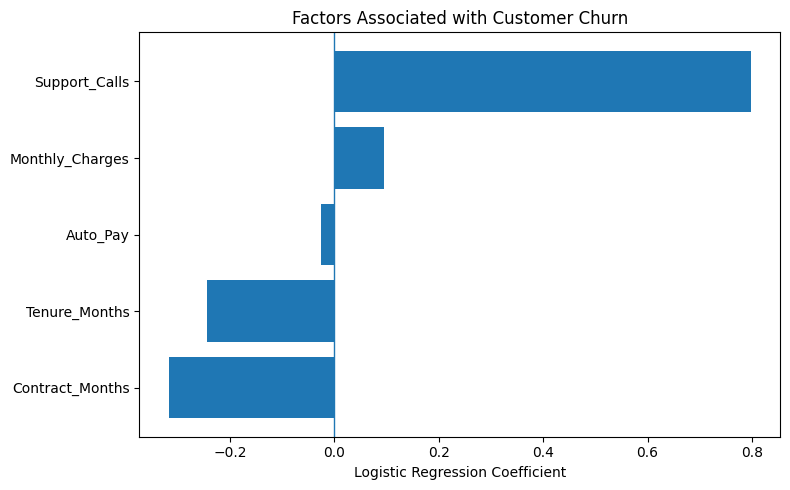

In [11]:
plt.figure(figsize=(8, 5))
plt.barh(coefficients["Feature"], coefficients["Coefficient"])
plt.axvline(0, linewidth=1)
plt.xlabel("Logistic Regression Coefficient")
plt.title("Factors Associated with Customer Churn")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [12]:
new_customers = pd.DataFrame({
    "Tenure_Months": [4, 36, 18],
    "Monthly_Charges": [105, 60, 95],
    "Support_Calls": [6, 1, 5],
    "Contract_Months": [1, 24, 12],
    "Auto_Pay": [0, 1, 0]
})

new_scaled = scaler.transform(new_customers)
new_prob = model.predict_proba(new_scaled)[:, 1]
new_customers["Churn_Probability"] = np.round(new_prob, 3)
new_customers["Risk_Level"] = np.where(new_prob >= 0.5, "High", "Low")
new_customers

,Tenure_Months,Monthly_Charges,Support_Calls,Contract_Months,Auto_Pay,Churn_Probability,Risk_Level
0,4,105,6,1,0,0.953,High
1,36,60,1,24,1,0.449,Low
2,18,95,5,12,0,0.883,High
